La regressione logistica

Una banca ha 10.000 clienti con la carta di credito (gli stessi dati della lezione 3). **Chi non riuscirà a pagare?** `default.csv`:
- `default` (la y): **1** se il cliente **non ha pagato** il debito della carta, **0** se l'ha pagato. Il **sì** è "non paga";
- `balance` (la x): il **saldo**, quanto il cliente **deve ancora** alla banca sulla carta, dopo aver pagato la rata del mese, in dollari. 0 vuol dire che ha ripagato tutto;
- `income`: il reddito annuo, in dollari;
- `student`: `Yes` se è uno studente, `No` se no.

**La cosa più importante è capire che cosa significano le variabili**, per interpretare correttamente i risultati: il sì (1) è il cliente che **non paga**, e il saldo è un **debito**, non i soldi sul conto. Più saldo vuol dire più debito da ripagare.

> **Per salvare il tuo lavoro scarica il notebook:** File → Scarica → Scarica .ipynb. Il file scaricato è tuo: per riaprirlo, su Colab File → Carica notebook, e da lì Salva funziona normalmente. Se hai aperto il notebook dal sito con *Apri in Colab*, non usare Salva: Colab proverebbe a salvarlo su GitHub.

In [ ]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf #modelli statistici: anche la regressione logistica
import math #per il numero e
from sklearn.metrics import confusion_matrix, classification_report #matrice di confusione e misure

In [ ]:
default = pl.read_csv("https://www.vincnardelli.com/msd/dati/default.csv") #carico i dati dal sito
default.head()

default,student,balance,income
i64,str,f64,f64
0,"""No""",729.526495,44361.625074
0,"""Yes""",817.180407,12106.1347
0,"""No""",1073.549164,31767.138947
0,"""No""",529.250605,35704.493935
0,"""No""",785.655883,38463.495879


In [ ]:
#333 clienti su 10.000 non hanno pagato (il 3,3%): quasi tutti pagano
default.filter(pl.col("default") == 1)

default,student,balance,income
i64,str,f64,f64
1,"""Yes""",1486.998122,17854.397028
1,"""Yes""",2205.799521,14271.492253
1,"""Yes""",1774.694223,20359.506086
1,"""No""",1889.59919,48956.171589
1,"""Yes""",1899.390626,20655.200003
…,…,…,…
1,"""No""",2148.898454,44309.917173
1,"""Yes""",1627.898323,17546.997016
1,"""No""",1750.25315,51578.940163


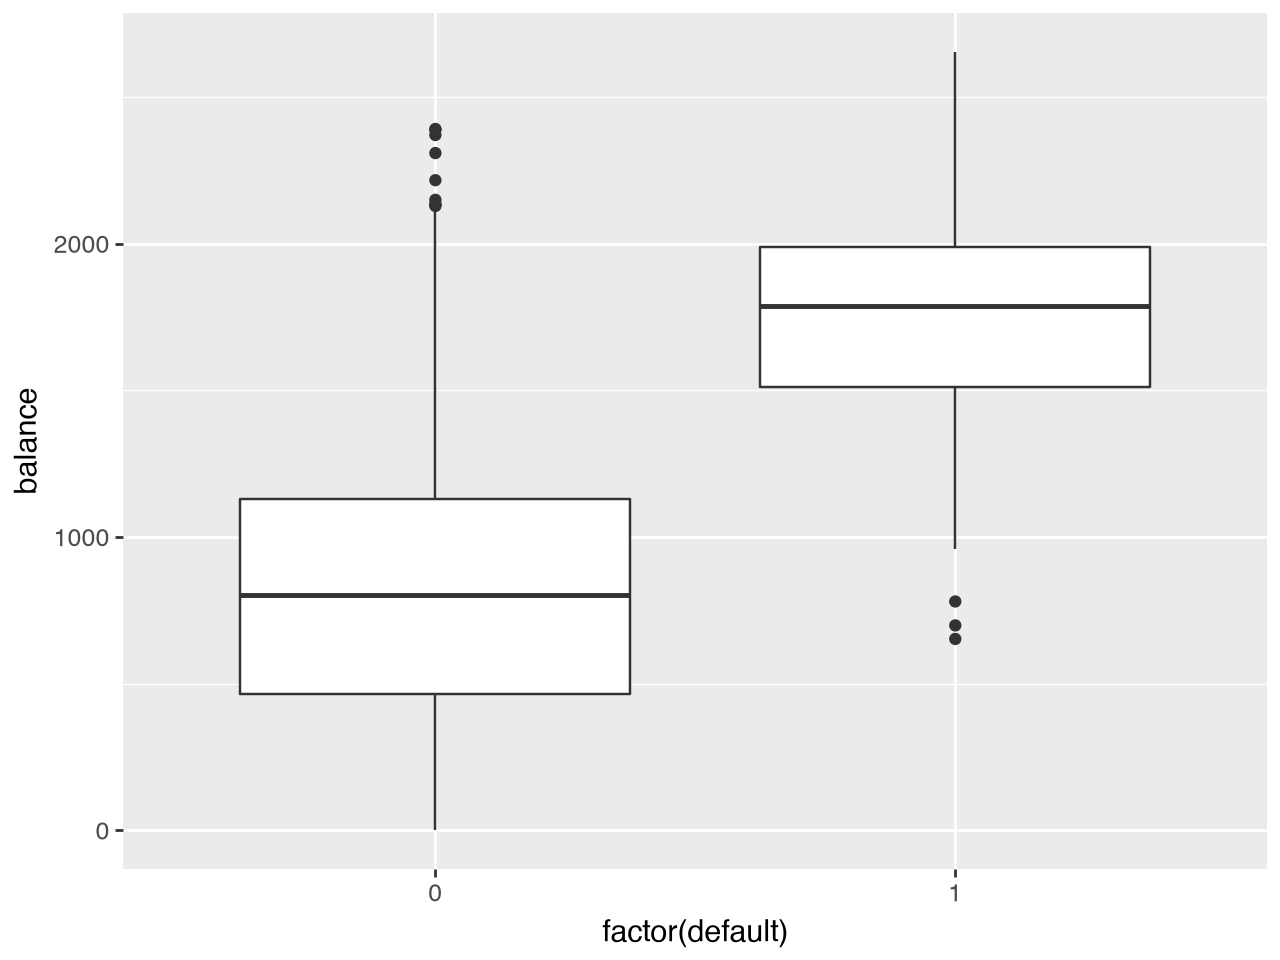

In [ ]:
#sulle x i due gruppi (0 paga, 1 non paga), sulle y la variabile numerica che confrontiamo, il saldo
#factor(default): default è un numero (0/1), factor lo usa come due gruppi, non come un numero su un asse
#chi non paga ha un saldo molto più alto (in media 1748 dollari, contro 804)
ggplot(default, aes(x="factor(default)", y="balance")) + geom_boxplot()

In [ ]:
#la y è 0/1: al posto di ols si usa logit
modello = smf.logit("default ~ balance", data=default).fit()

Optimization terminated successfully.
         Current function value: 0.079823
         Iterations 10


In [ ]:
#prob: una colonna nuova con la probabilità di non pagare che il modello dà a ogni cliente
#predict() senza nuovi dati la calcola per tutti i 10.000 clienti
default = default.with_columns(prob=modello.predict())
default.head()

default,student,balance,income,prob
i64,str,f64,f64,f64
0,"""No""",729.526495,44361.625074,0.001306
0,"""Yes""",817.180407,12106.1347,0.002113
0,"""No""",1073.549164,31767.138947,0.008595
0,"""No""",529.250605,35704.493935,0.000434
0,"""No""",785.655883,38463.495879,0.001777


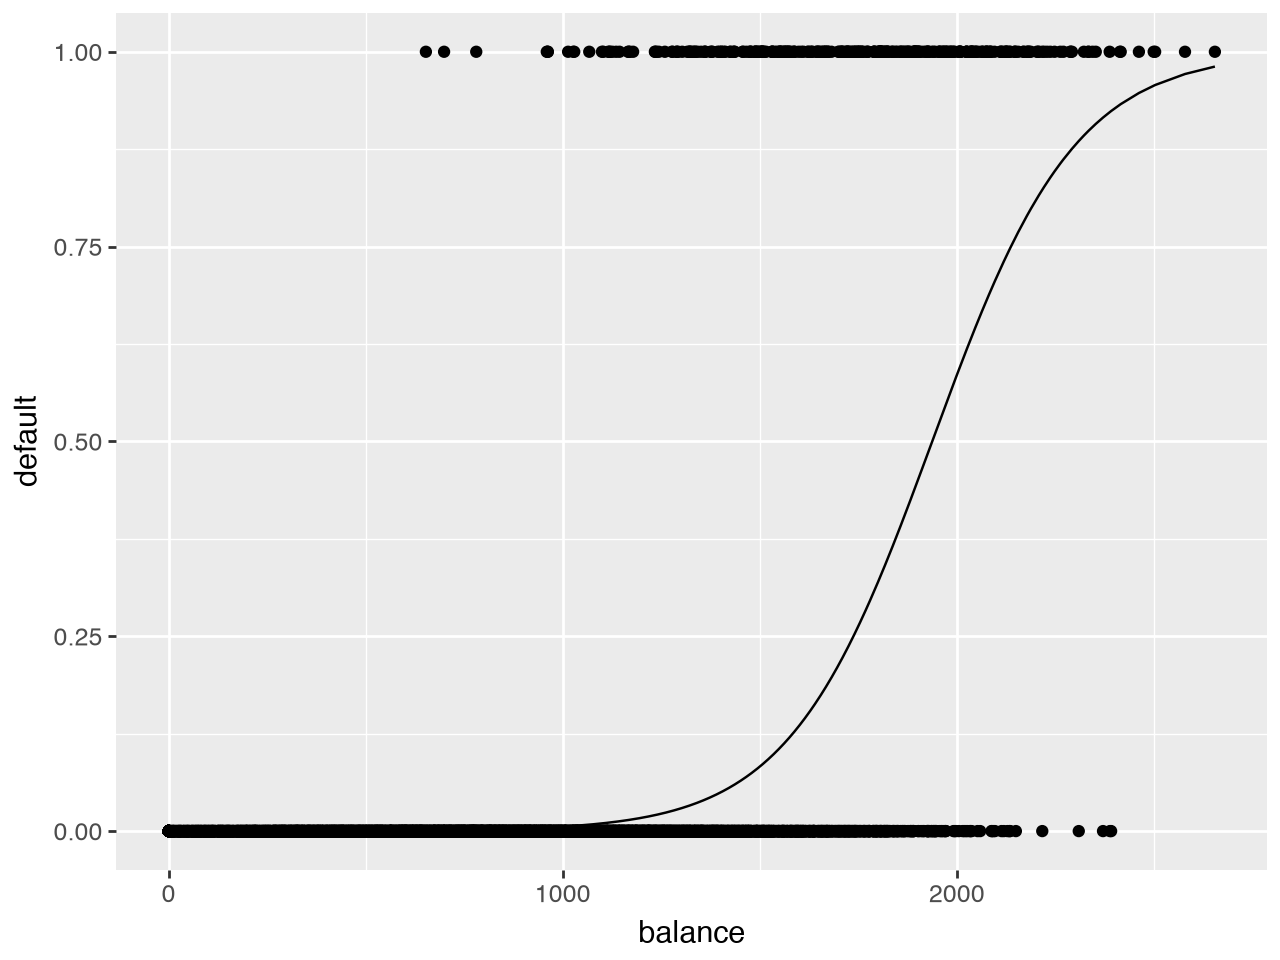

In [ ]:
#i punti sono la realtà (0 o 1); la curva è la colonna prob, la probabilità prevista per ogni saldo:
#per questo nella curva la y è "prob" e non "default"
#la curva resta sempre tra 0 e 1: con saldi bassi la probabilità di non pagare è quasi 0, poi sale a S
(ggplot(default, aes(x="balance", y="default")) + geom_point()
    + geom_line(aes(y="prob")))

In [ ]:
#i coefficienti sono log-odds: si legge il segno
#intercetta (beta0) -10.65: segno negativo, con saldo 0 è meno probabile che non paghi
#balance (beta1) +0.0055: segno positivo, più saldo, più è probabile che non paghi
#p-value 0.000 < 0.05: balance è significativa; Pseudo R-squ. 0.45: come l'R², va da 0 a 1
#(l'avviso "quasi-separation" sotto il summary si può ignorare)
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                default   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9998
Method:                           MLE   Df Model:                            1
Date:                Thu, 26 Nov 2026   Pseudo R-squ.:                  0.4534
Time:                        15:31:29   Log-Likelihood:                -798.23
converged:                       True   LL-Null:                       -1460.3
Covariance Type:            nonrobust   LLR p-value:                6.233e-290
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -10.6513      0.361    -29.491      0.000     -11.359      -9.943
balance        0.0055      0.000     24.952      0.000       0.005       0.006
==============================================================================

Possibly complete quasi-separation: A fraction 0.13 of observations can be
perfectly predicted. This might indicate that there is complete
quasi-separation. In this case some parameters will not be identified.
"""

In [ ]:
#due clienti: 100 dollari di saldo di differenza
nuovi = {"balance": [1900, 2000]}

In [ ]:
#nel risultato, 0 e 1 a sinistra non sono la y: sono la posizione dei valori che abbiamo dato a balance in nuovi
#in Python si conta da 0: 0 = il primo valore (1900 dollari), 1 = il secondo (2000 dollari)
#(lo 0 in alto è solo il nome della colonna del risultato)
#log-odds: la retta beta0 + beta1 * balance
#-10.65 + 0.0055 * 1900 = -0.20: negativo, è meno probabile che non paghi
#-10.65 + 0.0055 * 2000 = +0.35: positivo, è più probabile che non paghi
modello.predict(nuovi, which="linear")

0   -0.203388
1    0.346503
dtype: float64

In [ ]:
#odds: e elevato alla retta (ai log-odds)
#e^(-0.20) = 0.82: "82 a 100", ogni 100 clienti che pagano, 82 non pagano
#e^(0.35) = 1.41: "141 a 100", ogni 100 clienti che pagano, 141 non pagano
math.e ** modello.predict(nuovi, which="linear")

0    0.815961
1    1.414114
dtype: float64

In [ ]:
#probabilità: odds / (1 + odds); predict da solo fa tutti e tre i passi
#0.82 / (1 + 0.82) = 0.45: 82 su 182 clienti non pagano
#1.41 / (1 + 1.41) = 0.59: 141 su 241 clienti non pagano
modello.predict(nuovi)

0    0.449327
1    0.585769
dtype: float64

In [ ]:
#l'odds ratio è la variazione percentuale degli odds del sì (non pagare) quando la x sale
#si usa solo il coefficiente beta1, moltiplicato per quanto sale la x: e^(beta1 * dx)
#balance 1.0055 = e^0.0055: ogni dollaro di saldo in più, gli odds di non pagare si moltiplicano per 1.0055, cioè +0.55%
#(Intercept 0.000024 = e^-10.65 non è un odds ratio: sono gli odds di un cliente con saldo 0)
math.e ** modello.params

Intercept    0.000024
balance      1.005514
dtype: float64

In [ ]:
#100 dollari in più: e^(0.0055 * 100) = 1.73, gli odds di non pagare aumentano del 73%
#è il rapporto fra gli odds dei due clienti di prima: 1.41 / 0.82 = 1.73
#aumentano gli odds, non la probabilità (che passa da 0.45 a 0.59)
math.e ** (100 * modello.params["balance"])

np.float64(1.7330653054483085)

In [ ]:
#student è testo (Yes/No): la dummy student[T.Yes] la crea statsmodels; la categoria di riferimento è No
#summary2(): come summary(), ma mostra anche l'AIC
#student[T.Yes] -0.65: segno negativo, a parità di saldo e reddito per lo studente è meno probabile che non paghi; p-value 0.006, significativa
#income: p-value 0.71 > 0.05, income non è significativa (il coefficiente sembra 0.0000 perché il reddito è in dollari)
#Pseudo R-squared 0.462 (con il solo saldo 0.453): sale, ma sale sempre, anche con una x che non serve
modello_multi = smf.logit("default ~ balance + income + student", data=default).fit()
modello_multi.summary2()

Optimization terminated successfully.
         Current function value: 0.078577
         Iterations 10


<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Logit
==================================================================
Model:              Logit            Method:           MLE        
Dependent Variable: default          Pseudo R-squared: 0.462      
Date:               2026-11-26 15:31 AIC:              1579.5448  
No. Observations:   10000            BIC:              1608.3862  
Df Model:           3                Log-Likelihood:   -785.77    
Df Residuals:       9996             LL-Null:          -1460.3    
Converged:          1.0000           LLR p-value:      3.2575e-292
No. Iterations:     10.0000          Scale:            1.0000     
------------------------------------------------------------------
                 Coef.   Std.Err.    z     P>|z|   [0.025   0.975]
------------------------------------------------------------------
Intercept       -10.8690   0.4923 -22.0793 0.0000 -11.8339 -9.9042
student[T.Yes]   -0.6468   0.2363  -2.7376 0.0062  -1.1098 -0.1837
balance           0.0057   0.0002  24.7365 0.0000   0.0053  0.0062
income            0.0000   0.0000   0.3698 0.7115  -0.0000  0.0000
==================================================================

"""

In [ ]:
#per scegliere serve una misura che penalizza le x in più: nella lineare avremmo guardato l'R² aggiustato (il più alto),
#nella logistica si usa l'AIC: il più basso è il migliore
#senza income: Pseudo R-squared 0.462, uguale a quello con income; AIC 1577.7
modello_bs = smf.logit("default ~ balance + student", data=default).fit()
modello_bs.summary2()

Optimization terminated successfully.
         Current function value: 0.078584
         Iterations 10


<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Logit
==================================================================
Model:              Logit            Method:           MLE        
Dependent Variable: default          Pseudo R-squared: 0.462      
Date:               2026-11-26 15:31 AIC:              1577.6816  
No. Observations:   10000            BIC:              1599.3126  
Df Model:           2                Log-Likelihood:   -785.84    
Df Residuals:       9997             LL-Null:          -1460.3    
Converged:          1.0000           LLR p-value:      1.1893e-293
No. Iterations:     10.0000          Scale:            1.0000     
------------------------------------------------------------------
                Coef.   Std.Err.    z     P>|z|   [0.025   0.975] 
------------------------------------------------------------------
Intercept      -10.7495   0.3692 -29.1149 0.0000 -11.4731 -10.0259
student[T.Yes]  -0.7149   0.1475  -4.8459 0.0000  -1.0040  -0.4257
balance          0.0057   0.0002  24.7485 0.0000   0.0053   0.0062
==================================================================

"""

In [ ]:
#AIC: 1600.5 con il solo saldo, 1579.5 con saldo, reddito e studente, 1577.7 senza reddito
#il più basso è senza reddito: si sceglie default ~ balance + student
modello.aic, modello_multi.aic, modello_bs.aic

(np.float64(1600.451683490102),
 np.float64(1579.5448275789595),
 np.float64(1577.681597119209))

In [ ]:
#la soglia: sopra 0.5 prevediamo 1 (non paga), sotto 0 (paga); prima il reale, poi il previsto
#righe = reale (0 paga, 1 non paga), colonne = previsto (0 paga, 1 non paga)
#9625 veri negativi: previsto paga, e paga (indovinato)
#42 falsi positivi: previsto non paga, ma paga (un falso allarme)
#233 falsi negativi: previsto paga, ma non paga (un cliente rischioso che ci sfugge)
#100 veri positivi: previsto non paga, e non paga (indovinato)
confusion_matrix(default["default"], default["prob"] > 0.5)

array([[9625,   42],
       [ 233,  100]])

In [ ]:
#soglia 0.2: ci sfuggono meno clienti che non pagano (134), ma più falsi allarmi (263)
#cambia solo il previsto, il reale resta lo stesso
confusion_matrix(default["default"], default["prob"] > 0.2)

array([[9404,  263],
       [ 134,  199]])

In [ ]:
#soglia 0.8: pochissimi falsi allarmi (5), ma ci sfuggono quasi tutti quelli che non pagano (307)
#la soglia la sceglie la banca: se un cliente che non paga e ci sfugge costa più di un falso allarme, la abbassa
confusion_matrix(default["default"], default["prob"] > 0.8)

array([[9662,    5],
       [ 307,   26]])

In [ ]:
#accuracy 0.973 = accuratezza: indoviniamo 97 clienti su 100
#recall della riga "non paga (1)" 0.300 = sensitività: di chi non paga, ne troviamo solo 3 su 10
#recall della riga "paga (0)" 0.996 = specificità: di chi paga, ne riconosciamo quasi tutti
#attenzione: l'accuratezza è alta soprattutto perché quasi tutti pagano
#(dicendo a tutti "paga", senza modello, sarebbe 0.967): per trovare chi non paga conta la sensitività
#target_names dà un nome alle due righe, nell'ordine 0, 1: senza, le righe si chiamerebbero solo "0" e "1"
#digits=3: tre decimali; print lo mostra in colonna
print(classification_report(default["default"], default["prob"] > 0.5,
      target_names=["paga (0)", "non paga (1)"], digits=3))

              precision    recall  f1-score   support

    paga (0)      0.976     0.996     0.986      9667
non paga (1)      0.704     0.300     0.421       333

    accuracy                          0.973     10000
   macro avg      0.840     0.648     0.703     10000
weighted avg      0.967     0.973     0.967     10000

